In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import altair as alt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm

from dice.agents import Agent, SmartAgent
from dice.game import FillOrBust
from train_dice_agents import plot_training_metric, train

alt.renderers.set_embed_options(theme="dark")

RendererRegistry.enable('default')

In [40]:
n_episodes = 10_000
start_learning_rate = 0.0001
lr_decay = start_learning_rate / (n_episodes // 3)
final_lr = 0.0001
start_epsilon = 1.0
epsilon_decay = start_epsilon / (n_episodes // 2)
final_epsilon = 0.1
discount_factor = 0.8

kwargs = dict(
    initial_learning_rate=start_learning_rate,
    learning_rate_decay=lr_decay,
    final_learning_rate=final_lr,
    initial_epsilon=start_epsilon,
    epsilon_decay=epsilon_decay,
    final_epsilon=final_epsilon,
    discount_factor=discount_factor,
)

In [41]:
smart1 = SmartAgent("smart1", **kwargs)
smart2 = SmartAgent("smart2", **kwargs)
smart3 = SmartAgent("smart3", **kwargs)
smart4 = SmartAgent("smart4", **kwargs)
dumb = Agent("dumb")

agents: list[Agent] = [smart1, dumb]

train(agents, n_episodes=n_episodes)

100%|██████████| 10000/10000 [00:27<00:00, 368.79it/s]


In [42]:
for agent in agents:
    print(f"{agent.name:6}: {agent.wins:5} {100 * agent.wins / n_episodes:.1f}%")

smart1:  7128 71.3%
dumb  :  2872 28.7%


In [43]:
plot_training_metric(smart1, metric="num_turns_in_game")

Median `num_turns_in_game` after training: 34.5


alt.LayerChart(...)

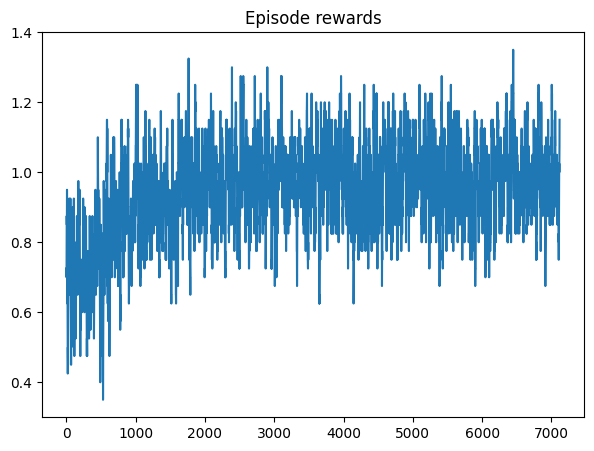

In [44]:
rolling_length = n_episodes // 1000
fig, ax = plt.subplots(ncols=1, figsize=(7, 5))
ax.set_title("Episode rewards")
# compute and assign a rolling average of the data to provide a smoother graph
reward_moving_average = (
    np.convolve(
        np.array(smart1.episode_rewards).flatten(), np.ones(rolling_length), mode="valid"
    )
    / rolling_length
)
ax.plot(range(len(reward_moving_average)), reward_moving_average)
plt.show()

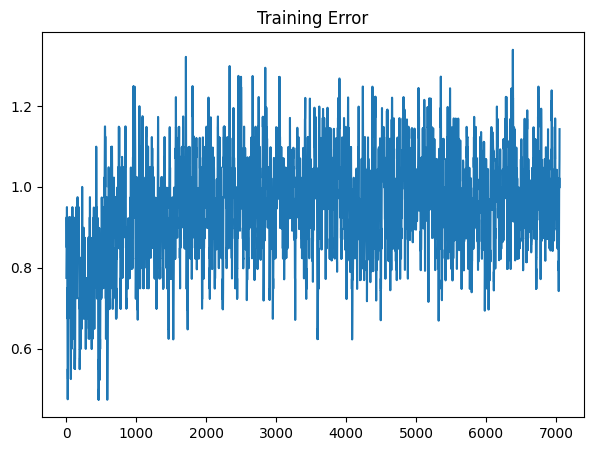

In [45]:
rolling_length = n_episodes // 1000
fig, ax = plt.subplots(ncols=1, figsize=(7, 5))
ax.set_title("Training Error")
# compute and assign a rolling average of the data to provide a smoother graph
reward_moving_average = (
    np.convolve(
        np.array(smart1.training_error).flatten(), np.ones(rolling_length), mode="valid"
    )
    / rolling_length
)
ax.plot(range(len(reward_moving_average)), reward_moving_average)
plt.show()